# Coffee Shop Sales — Exploratory Data Analysis

This project explores coffee shop transactions using Python, Pandas, Matplotlib and Seaborn. The objective is to understand sales performance, order patterns and revenue drivers.

Place `coffee_shop_final.csv` in the same folder as this notebook. Results are generated from the supplied dataset. Customer names are not used in the analysis.

## 1. Data overview

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("coffee_shop_final.csv")
# Customer names are not needed for this analysis.
df = df.drop(columns=["Customer"], errors="ignore")

In [2]:
df.head()

,Order_ID,Date,Product,Quantity,Price,Total,Payment_Method,Month,Day_Name,Is_Weekend,Order_Size,Revenue_Category
0,10493,2026-02-02,Mocha,2,6.5,13.0,Cash,2.0,Monday,False,Small,Low Revenue
1,10384,2026-03-02,Espresso,1,3.5,3.5,Card,3.0,Monday,False,Small,Low Revenue
2,10857,NaN,Espresso,4,3.5,14.0,Card,NaN,NaN,False,Medium,Low Revenue
3,10835,2026-02-20,Tea,4,3.0,12.0,Card,2.0,Friday,False,Medium,Low Revenue
4,10604,2026-01-30,Latte,2,5.5,11.0,Card,1.0,Friday,False,Small,Low Revenue


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Column names:", df.columns.tolist())
print("Column data types:", df.dtypes)
df.info()

Number of rows: 970
Number of columns: 12
Column names: ['Order_ID', 'Date', 'Product', 'Quantity', 'Price', 'Total', 'Payment_Method', 'Month', 'Day_Name', 'Is_Weekend', 'Order_Size', 'Revenue_Category']
Column data types: Order_ID              int64
Date                 object
Product              object
Quantity              int64
Price               float64
Total               float64
Payment_Method       object
Month               float64
Day_Name             object
Is_Weekend             bool
Order_Size           object
Revenue_Category     object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 970 entries, 0 to 969
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          970 non-null    int64  
 1   Date              864 non-null    object 
 2   Product           949 non-null    object 
 3   Quantity          970 non-null    int64  
 4   Price             970 non-null    

In [4]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(numerical_columns)
categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()
print(categorical_columns)
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
date_columns = df.select_dtypes(include=['datetime64']).columns.tolist()
print(date_columns)
boolean_columns = df.select_dtypes(include=['bool']).columns.tolist()
print(boolean_columns)

# Use only known dates for calendar-based analysis.
dated_df = df.dropna(subset=["Date"]).copy()
dated_df["Day_Name"] = dated_df["Date"].dt.day_name()
dated_df["Is_Weekend"] = dated_df["Date"].dt.dayofweek >= 5

['Order_ID', 'Quantity', 'Price', 'Total', 'Month']
['Date', 'Product', 'Payment_Method', 'Day_Name', 'Order_Size', 'Revenue_Category']
['Date']
['Is_Weekend']


In [5]:
print(df.describe())

           Order_ID                 Date  ...       Total       Month
count    970.000000                  864  ...  970.000000  864.000000
mean   10485.500000  2026-04-16 01:55:00  ...   12.946392    4.016204
min    10001.000000  2026-01-01 00:00:00  ...    3.000000    1.000000
25%    10243.250000  2026-02-21 00:00:00  ...    6.000000    2.000000
50%    10485.500000  2026-04-15 00:00:00  ...   11.000000    4.000000
75%    10727.750000  2026-06-07 00:00:00  ...   18.000000    6.000000
max    10970.000000  2026-07-29 00:00:00  ...   42.500000    7.000000
std      280.159181                  NaN  ...    8.715087    1.970752

[8 rows x 6 columns]


### Data quality checks

In [6]:
# Check data quality without changing recorded transaction values.
expected_total = df["Quantity"] * df["Price"]
revenue_mismatch = (expected_total - df["Total"]).abs() > 0.01
print("Missing dates:", df["Date"].isna().sum())
print("Missing product names:", df["Product"].isna().sum())
print("Revenue mismatches:", revenue_mismatch.sum())
print("Duplicate order IDs:", df["Order_ID"].duplicated().sum())
print("Revenue with unknown product:", df.loc[df["Product"].isna(), "Total"].sum(), "AZN")

Missing dates: 106
Missing product names: 21
Revenue mismatches: 65
Duplicate order IDs: 0
Revenue with unknown product: 218.5 AZN


## 2. Key sales metrics

In [7]:
print("Total number of orders:",df.shape[0])

Total number of orders: 970


In [8]:
print("Total revenue:", df['Total'].sum(),"AZN")

Total revenue: 12558.0 AZN


In [9]:
print("Average revenue:", df['Total'].sum() / df.shape[0], "AZN")

Average revenue: 12.94639175257732 AZN


In [10]:
print("Mean:", df['Total'].mean())
print("Median:", df['Total'].median())
print("Mode:", df['Total'].mode())
print("Minimum:", df['Total'].min())
print("Maximum:", df['Total'].max())
print("Standard Deviation:", df['Total'].std())
print("Q1:", df['Total'].quantile(0.25))
print("Q3:", df['Total'].quantile(0.75))

Mean: 12.94639175257732
Median: 11.0
Mode: 0    6.0
Name: Total, dtype: float64
Minimum: 3.0
Maximum: 42.5
Standard Deviation: 8.715087351543296
Q1: 6.0
Q3: 18.0


**Finding:** The original dataset contains 970 records, with total revenue of 12,558 AZN and an average revenue of approximately 12.95 AZN per record.

## 3. Product performance

In [11]:
product_orders = df.groupby('Product')['Order_ID'].count()
print(product_orders.sort_values(ascending=False))

Product
Latte         180
Mocha         169
Americano     155
Tea           153
Cappuccino    147
Espresso      145
Name: Order_ID, dtype: int64


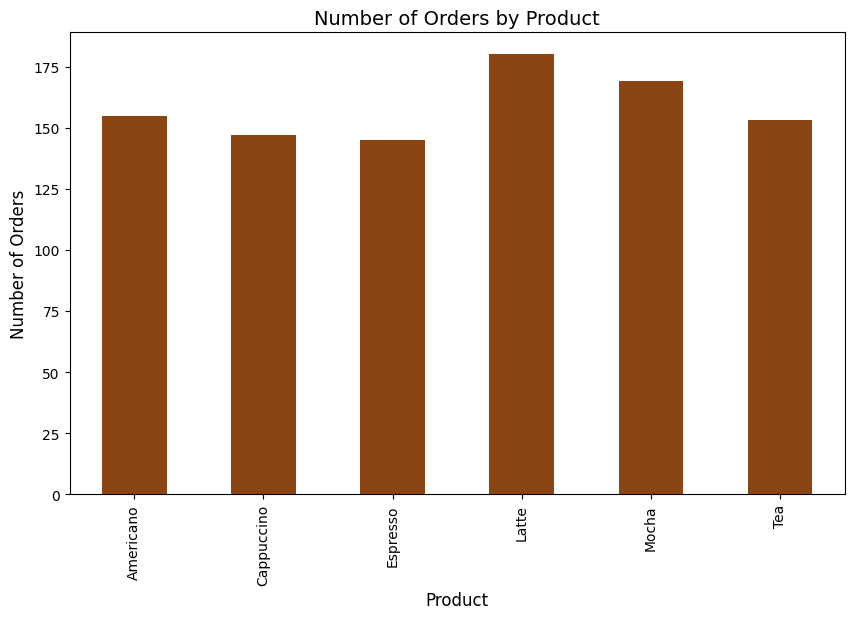

In [12]:
plt.figure(figsize=(10, 6))
product_orders.plot(kind='bar', color='saddlebrown')
plt.title('Number of Orders by Product', fontsize=14)
plt.xlabel('Product', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.show()

In [13]:
print(df.groupby('Product')['Quantity'].sum().sort_values(ascending=False))

Product
Latte         512
Mocha         461
Cappuccino    397
Tea           382
Americano     380
Espresso      365
Name: Quantity, dtype: int64


In [14]:
product_analysis = df.groupby("Product").agg(
    Order_Count=("Order_ID", "count"),
    Total_Revenue=("Total", "sum"),
    Average_Order_Amount=("Total", "mean"),
    Median_Order_Amount=("Total", "median")
)
print(product_analysis)

            Order_Count  ...  Median_Order_Amount
Product                  ...                     
Americano           155  ...                  8.0
Cappuccino          147  ...                 12.0
Espresso            145  ...                  7.0
Latte               180  ...                 16.5
Mocha               169  ...                 13.0
Tea                 153  ...                  6.0

[6 rows x 4 columns]


In [15]:
product_revenue = df.groupby("Product")["Total"].sum().reset_index()
print(product_revenue)

      Product   Total
0   Americano  1547.0
1  Cappuccino  2433.0
2    Espresso  1301.5
3       Latte  2866.5
4       Mocha  3030.5
5         Tea  1161.0


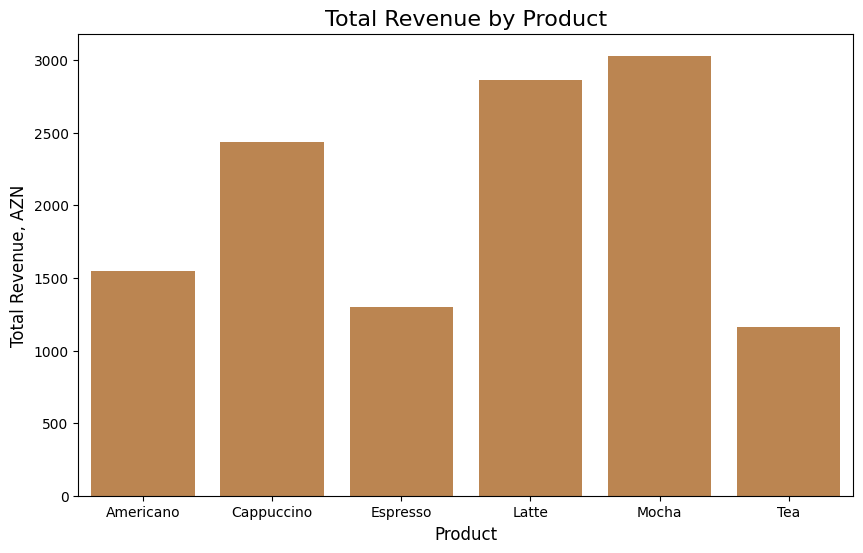

In [16]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=product_revenue,
    x="Product",
    y="Total",
    color="peru"
)
plt.title("Total Revenue by Product", fontsize=16)
plt.xlabel("Product", fontsize=12)
plt.ylabel("Total Revenue, AZN", fontsize=12)
plt.show()

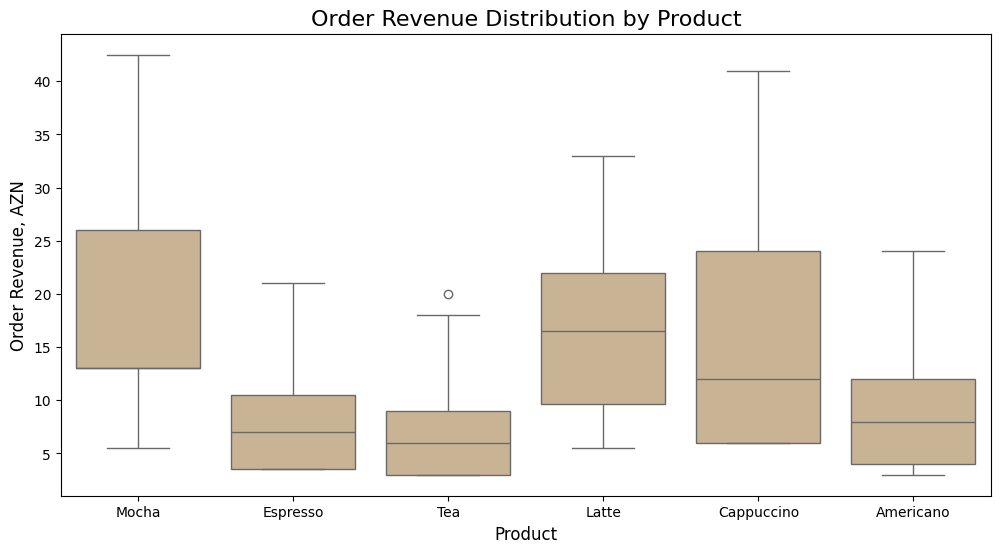

In [17]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x="Product",
    y="Total",
    color="tan"
)
plt.title("Order Revenue Distribution by Product", fontsize=16)
plt.xlabel("Product", fontsize=12)
plt.ylabel("Order Revenue, AZN", fontsize=12)
plt.show()

**Finding:** Latte leads in quantity sold, while Mocha generates the highest revenue. Product prices and quantities both matter.

## 4. Payment methods

In [18]:
payment_counts = df['Payment_Method'].value_counts()
card_count = payment_counts['Card']
print(card_count)
total_count = df['Payment_Method'].count()
print(total_count)
card_percentage = (card_count / total_count) * 100
print("Card payment percentage:", round(card_percentage, 2), "%")

638
970
Card payment percentage: 65.77 %


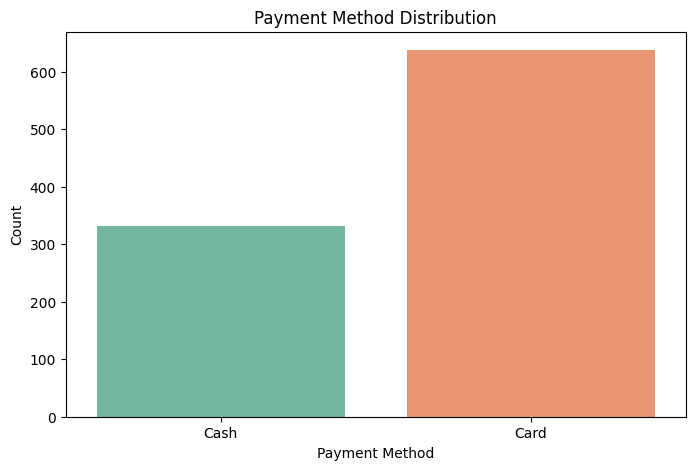

In [19]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Payment_Method', hue='Payment_Method', palette='Set2', dodge=False)
if plt.gca().get_legend() is not None:
    plt.gca().get_legend().remove()
plt.title('Payment Method Distribution')
plt.xlabel('Payment Method')
plt.ylabel('Count')
plt.show()

In [20]:
payment_analysis = df.groupby("Payment_Method").agg(
    Order_Count=("Order_ID", "count"),
    Total_Revenue=("Total", "sum"),
    Average_Order_Amount=("Total", "mean"),
    Median_Order_Amount=("Total", "median")
)
print(payment_analysis)

                Order_Count  ...  Median_Order_Amount
Payment_Method               ...                     
Card                    638  ...                 11.0
Cash                    332  ...                 11.0

[2 rows x 4 columns]


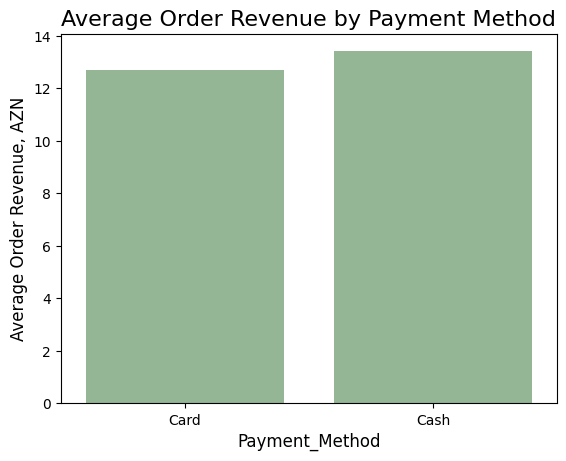

In [21]:
sns.barplot(
    data=payment_analysis.reset_index(),
    x="Payment_Method",
    y="Average_Order_Amount",
    color="darkseagreen"
)
plt.title("Average Order Revenue by Payment Method", fontsize=16)
plt.xlabel("Payment_Method", fontsize=12)
plt.ylabel("Average Order Revenue, AZN", fontsize=12)
plt.show()

**Finding:** Card payments account for 638 of 970 records. Cash payments have a slightly higher average order amount.

## 5. Order size and revenue distribution

In [22]:
order_counts = df['Order_Size'].value_counts().sort_values(ascending=False)
print(order_counts)

Order_Size
Small     543
Medium    292
Large     135
Name: count, dtype: int64


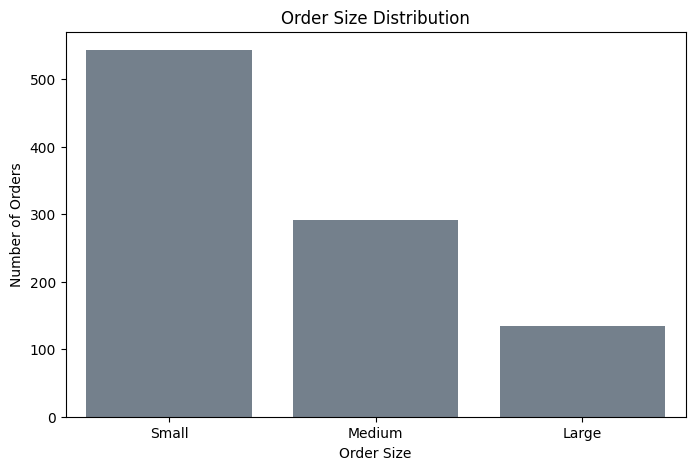

In [23]:
plt.figure(figsize=(8, 5))
sns.countplot( data=df, x='Order_Size', order=['Small', 'Medium', 'Large'],color='slategray')
plt.title('Order Size Distribution')
plt.xlabel('Order Size')
plt.ylabel('Number of Orders')
plt.show()

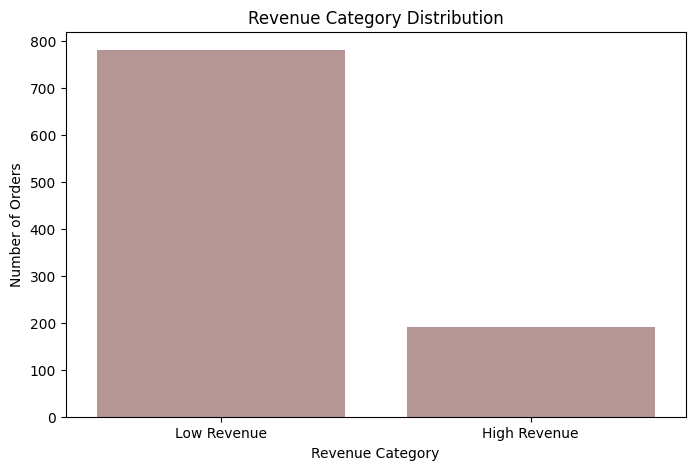

In [24]:
plt.figure(figsize=(8, 5))
sns.countplot( data=df, x='Revenue_Category',color='rosybrown')
plt.title('Revenue Category Distribution')
plt.xlabel('Revenue Category')
plt.ylabel('Number of Orders')
plt.show()

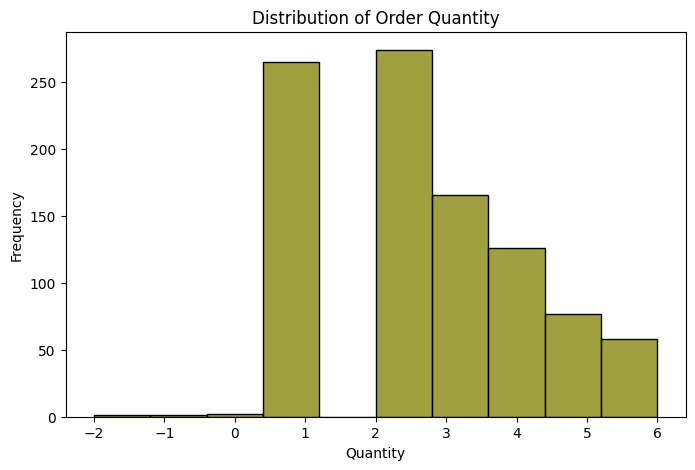

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Quantity', bins=10, color='olive')
plt.title('Distribution of Order Quantity')
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.show()

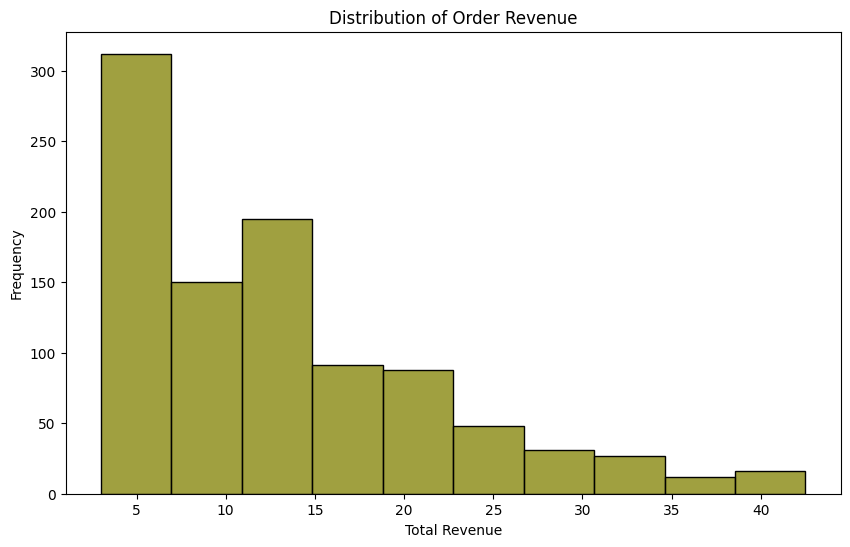

In [26]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Total', bins=10, color='olive')
plt.title('Distribution of Order Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Frequency')
plt.show()

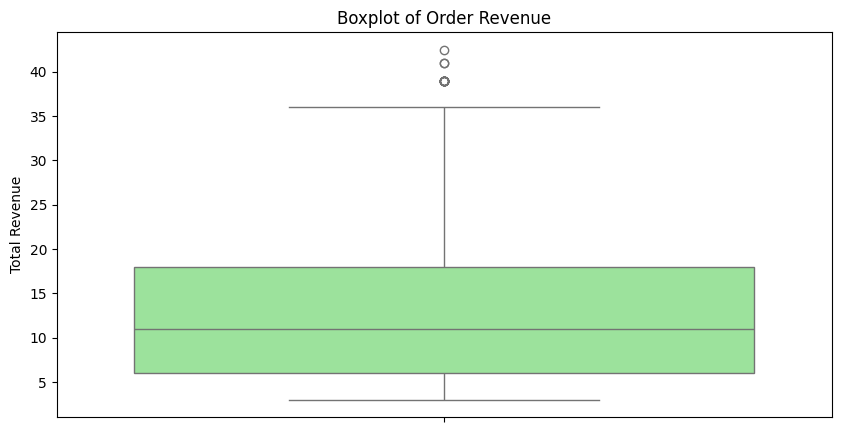

In [27]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, y='Total', color='lightgreen')
plt.title('Boxplot of Order Revenue')
plt.ylabel('Total Revenue')
plt.show()

In [28]:
Q1 = df['Total'].quantile(0.25)
Q3 = df['Total'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

high_orders = df[df['Total'] > upper_limit]

print("Upper Limit:", upper_limit)
print(high_orders[[ 'Product', 'Total']])

Upper Limit: 36.0
        Product  Total
59        Mocha   39.0
90   Cappuccino   41.0
113       Mocha   39.0
145       Mocha   39.0
203       Mocha   39.0
261       Mocha   39.0
410       Mocha   42.5
503       Mocha   39.0
532       Mocha   39.0
561       Mocha   39.0
716  Cappuccino   41.0
802       Mocha   39.0
812       Mocha   39.0
839       Mocha   39.0
856       Mocha   39.0
865       Mocha   39.0


## 6. Sales by day

In [29]:
days_order = ['Monday', 'Tuesday', 'Wednesday',
              'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = dated_df['Day_Name'].value_counts().reindex(days_order, fill_value=0)
print(day_counts)
print("Day with most orders:", day_counts.idxmax())
print("Day with fewest orders:", day_counts.idxmin())

Day_Name
Monday       122
Tuesday      124
Wednesday    110
Thursday     123
Friday       150
Saturday     111
Sunday       124
Name: count, dtype: int64
Day with most orders: Friday
Day with fewest orders: Wednesday


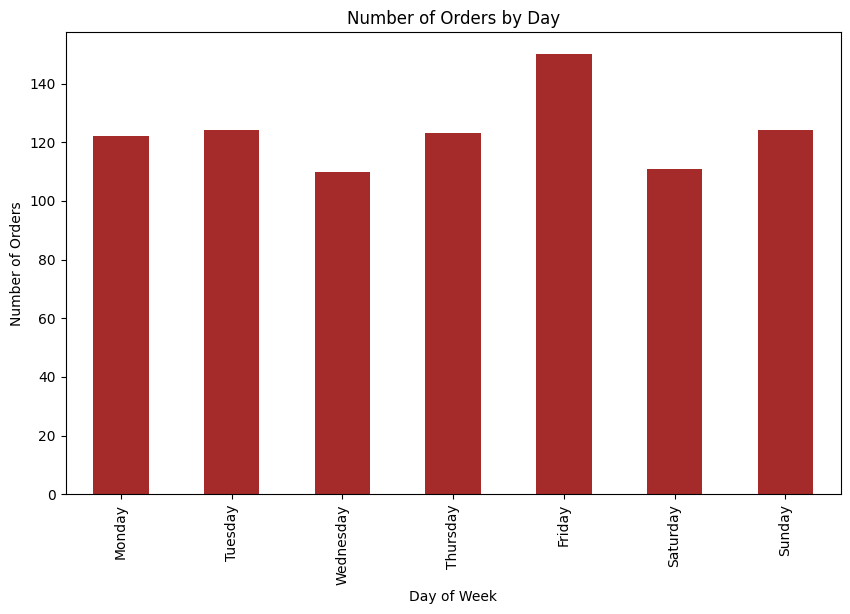

In [30]:
plt.figure(figsize=(10, 6))
day_counts.plot(kind='bar', color='brown')
plt.title('Number of Orders by Day')
plt.xlabel('Day of Week')
plt.ylabel('Number of Orders')
plt.show()

In [31]:
day_analysis = dated_df.groupby("Is_Weekend").agg(
    Order_Count=("Order_ID", "count"),
    Total_Revenue=("Total", "sum"),
    Average_Revenue=("Total", "mean"),
    Median_Revenue=("Total", "median")
)

day_analysis = day_analysis.rename(
    index={False: "Weekday", True: "Weekend"})

print(day_analysis)
day_analysis.index.name = "Day_Type"
print("Orders excluded due to missing dates:", len(df) - len(dated_df))

            Order_Count  Total_Revenue  Average_Revenue  Median_Revenue
Is_Weekend                                                             
Weekday             629         8149.5        12.956280            11.0
Weekend             235         3018.0        12.842553            11.0
Orders excluded due to missing dates: 106


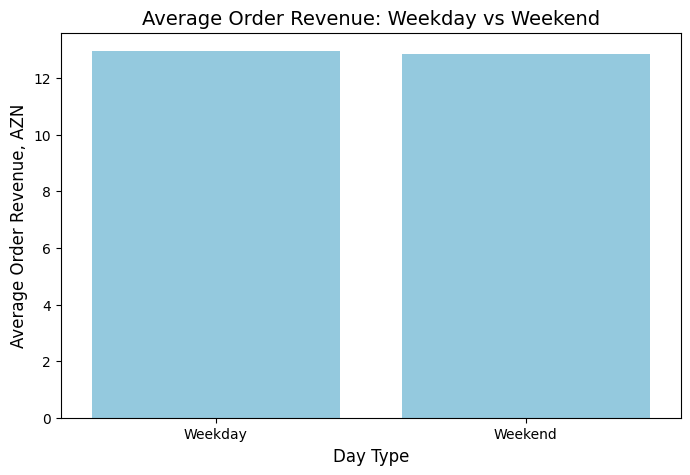

In [32]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=day_analysis.reset_index(),
    x="Day_Type",
    y="Average_Revenue",
    color="skyblue"
)
plt.title("Average Order Revenue: Weekday vs Weekend", fontsize=14)
plt.xlabel("Day Type", fontsize=12)
plt.ylabel("Average Order Revenue, AZN", fontsize=12)
plt.show()

In [33]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_analysis = dated_df.groupby("Day_Name").agg(
    Order_Count=("Order_ID", "count"),
    Total_Revenue=("Total", "sum"),
    Average_Order_Amount=("Total", "mean")
)

print(weekday_analysis)

weekday_analysis = weekday_analysis.reindex(day_order)
print(weekday_analysis)

           Order_Count  Total_Revenue  Average_Order_Amount
Day_Name                                                   
Friday             150         1973.0             13.153333
Monday             122         1503.5             12.323770
Saturday           111         1498.0             13.495495
Sunday             124         1520.0             12.258065
Thursday           123         1785.5             14.516260
Tuesday            124         1605.5             12.947581
Wednesday          110         1282.0             11.654545
           Order_Count  Total_Revenue  Average_Order_Amount
Day_Name                                                   
Monday             122         1503.5             12.323770
Tuesday            124         1605.5             12.947581
Wednesday          110         1282.0             11.654545
Thursday           123         1785.5             14.516260
Friday             150         1973.0             13.153333
Saturday           111         1498.0   

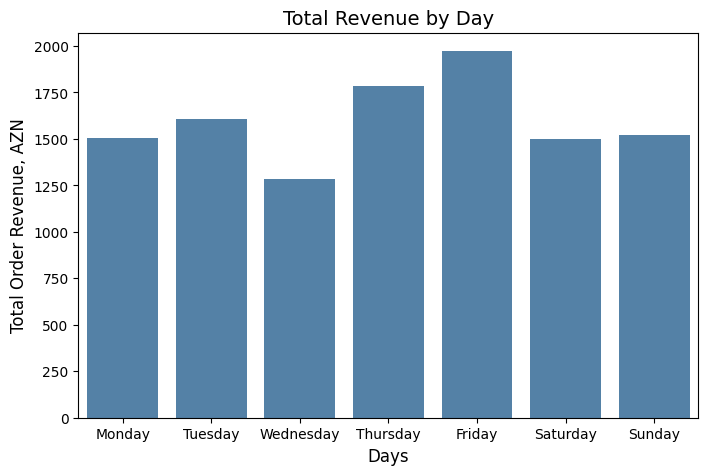

In [34]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=weekday_analysis.reset_index(),
    x="Day_Name",
    y="Total_Revenue",
    color="steelblue"
)
plt.title("Total Revenue by Day", fontsize=14)
plt.xlabel("Days", fontsize=12)
plt.ylabel("Total Order Revenue, AZN", fontsize=12)
plt.show()

In [35]:
result = dated_df.groupby('Date')['Quantity'].sum()
print("Date with highest quantity sold:", result.idxmax(), result.max())
print("Date with lowest quantity sold:", result.idxmin(), result.min())

Date with highest quantity sold: 2026-01-23 00:00:00 28
Date with lowest quantity sold: 2026-02-24 00:00:00 0


**Finding:** Among the 864 orders with valid dates, 629 weekday orders generated 8,149.50 AZN and 235 weekend orders generated 3,018 AZN. The 106 undated orders (1,390.50 AZN) are excluded from calendar-based analyses only. Total weekday and weekend revenue is not directly comparable as a daily rate because the groups contain different numbers of days.

## 7. Relationships between variables

In [36]:
quantity_analysis = df.groupby("Quantity").agg(
    Order_Count=("Order_ID", "count"),
    Average_Total=("Total", "mean"),
    Median_Total=("Total", "median"),
    Total_Revenue=("Total", "sum")
)

print(quantity_analysis)

          Order_Count  Average_Total  Median_Total  Total_Revenue
Quantity                                                         
-2                  1       6.000000           6.0            6.0
-1                  1       3.000000           3.0            3.0
 0                  2      15.000000          15.0           30.0
 1                265       4.818868           4.0         1277.0
 2                274       9.830292          11.0         2693.5
 3                166      14.003012          12.0         2324.5
 4                126      19.666667          22.0         2478.0
 5                 77      24.805195          27.5         1910.0
 6                 58      31.655172          33.0         1836.0


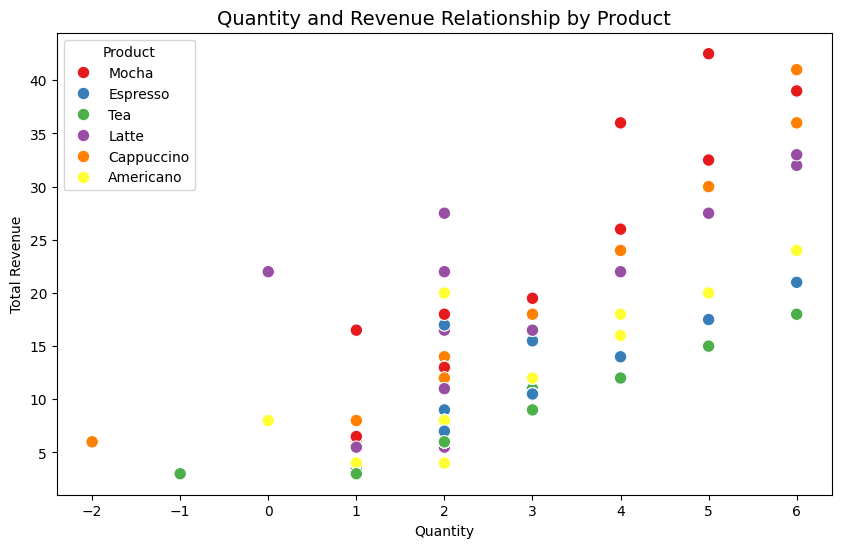

In [37]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Total",
    hue="Product",
    palette="Set1",
    s=80
)

plt.title("Quantity and Revenue Relationship by Product", fontsize=14)
plt.xlabel("Quantity")
plt.ylabel("Total Revenue")
plt.legend(title="Product")
plt.show()

In [38]:
correlation = df["Quantity"].corr(df["Total"])

print("Correlation:", correlation)

print("Correlation indicates a strong positive association in this dataset.")

Correlation: 0.8740934439502843
Correlation indicates a strong positive association in this dataset.


In [39]:
order_size_analysis = df.groupby(
    ["Product", "Order_Size"]
).size().unstack(fill_value=0)

print(order_size_analysis)

Order_Size  Large  Medium  Small
Product                         
Americano      19      42     94
Cappuccino     26      39     82
Espresso       15      46     84
Latte          31      58     91
Mocha          26      52     91
Tea            15      52     86


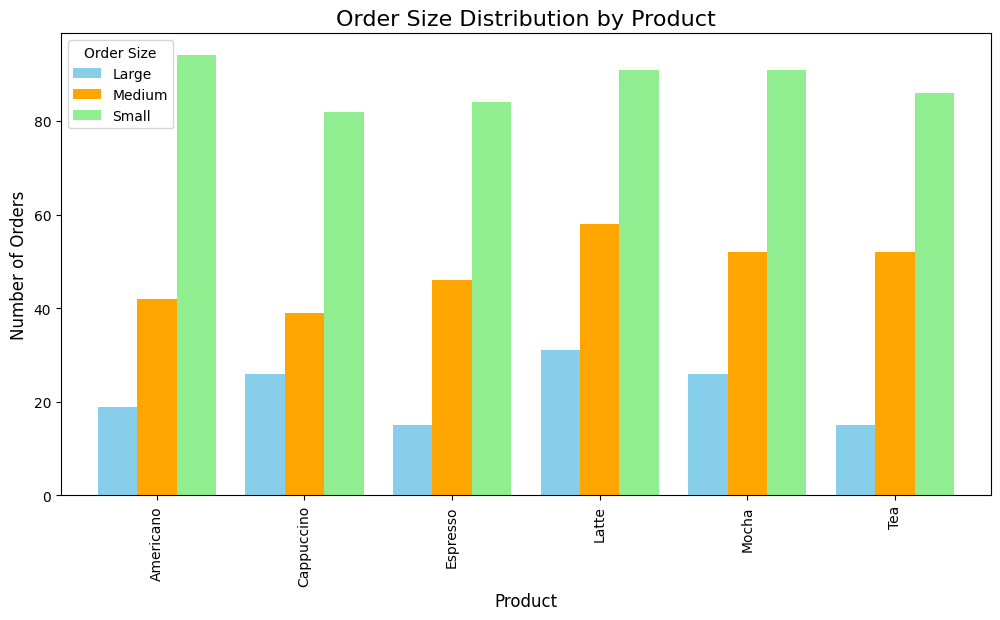

In [40]:
order_size_analysis.plot(
    kind="bar",
    figsize=(12, 6),
    color=["skyblue", "orange", "lightgreen"],
    width=0.8
)
plt.title("Order Size Distribution by Product", fontsize=16)
plt.xlabel("Product", fontsize=12)
plt.ylabel("Number of Orders", fontsize=12)
plt.legend(title="Order Size")
plt.show()

In [41]:
payment_methods_analysis = df.groupby(
    ["Payment_Method", "Revenue_Category"]
).size().unstack(fill_value=0)

print(payment_methods_analysis)

Revenue_Category  High Revenue  Low Revenue
Payment_Method                             
Card                       116          522
Cash                        74          258


In [42]:
payment_methods_percentage = payment_methods_analysis.div(
    payment_methods_analysis.sum(axis=1),
    axis=0
) * 100

print(payment_methods_percentage.round(2))

Revenue_Category  High Revenue  Low Revenue
Payment_Method                             
Card                     18.18        81.82
Cash                     22.29        77.71


**Finding:** Quantity and total revenue have a positive relationship. Different product prices explain why identical quantities can produce different revenue amounts.

## 8. Multivariate analysis

In [43]:
result = dated_df.groupby(
    ["Product", "Is_Weekend"]
).agg(
    Order_Count=("Total", "count"),
    Total_Revenue=("Total", "sum"),
    Average_Order=("Total", "mean"),
    Median_Order=("Total", "median")
).reset_index()

result["Is_Weekend"] = result["Is_Weekend"].map({
    False: "Weekday",
    True: "Weekend"
})

print(result)

       Product Is_Weekend  ...  Average_Order  Median_Order
0    Americano    Weekday  ...      10.721154           8.0
1    Americano    Weekend  ...       8.857143           8.0
2   Cappuccino    Weekday  ...      16.674157          12.0
3   Cappuccino    Weekend  ...      16.461538          12.0
4     Espresso    Weekday  ...       9.028736           7.0
5     Espresso    Weekend  ...       9.500000           7.0
6        Latte    Weekday  ...      15.798387          16.5
7        Latte    Weekend  ...      16.365854          11.0
8        Mocha    Weekday  ...      17.357143          13.0
9        Mocha    Weekend  ...      17.083333          13.0
10         Tea    Weekday  ...       7.504950           6.0
11         Tea    Weekend  ...       7.419355           6.0

[12 rows x 6 columns]


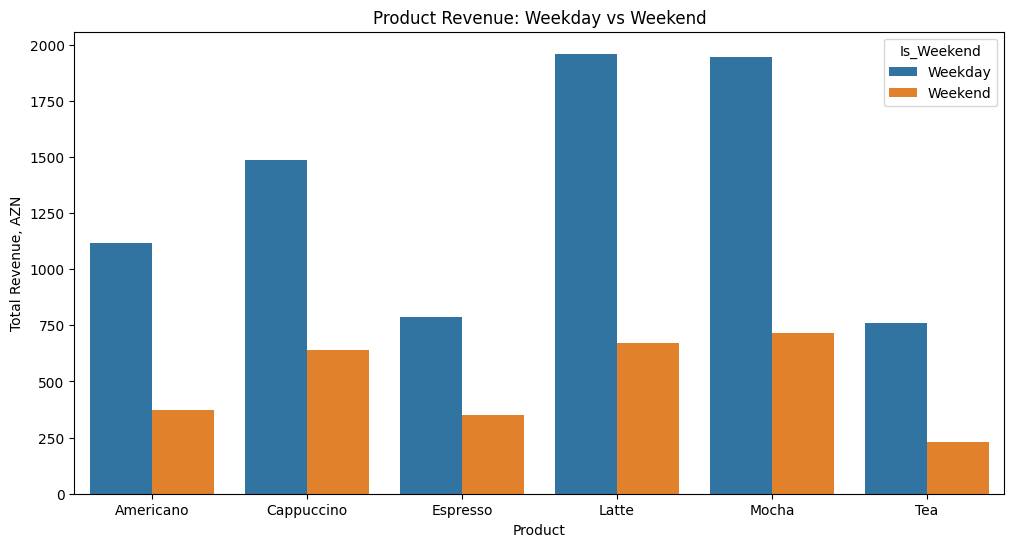

In [44]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=result,
    x="Product",
    y="Total_Revenue",
    hue="Is_Weekend"
)

plt.title("Product Revenue: Weekday vs Weekend")
plt.xlabel("Product")
plt.ylabel("Total Revenue, AZN")
plt.legend(title="Is_Weekend")
plt.show()

In [45]:
payment_result = df.groupby(
    ["Product", "Payment_Method"]
).agg(
    Order_Count=("Total", "count"),
    Total_Revenue=("Total", "sum"),
    Average_Order=("Total", "mean")
).reset_index()

print(payment_result)

       Product Payment_Method  Order_Count  Total_Revenue  Average_Order
0    Americano           Card          106         1051.0       9.915094
1    Americano           Cash           49          496.0      10.122449
2   Cappuccino           Card           95         1518.0      15.978947
3   Cappuccino           Cash           52          915.0      17.596154
4     Espresso           Card          100          927.5       9.275000
5     Espresso           Cash           45          374.0       8.311111
6        Latte           Card          115         1839.0      15.991304
7        Latte           Cash           65         1027.5      15.807692
8        Mocha           Card          108         1883.0      17.435185
9        Mocha           Cash           61         1147.5      18.811475
10         Tea           Card          102          780.0       7.647059
11         Tea           Cash           51          381.0       7.470588


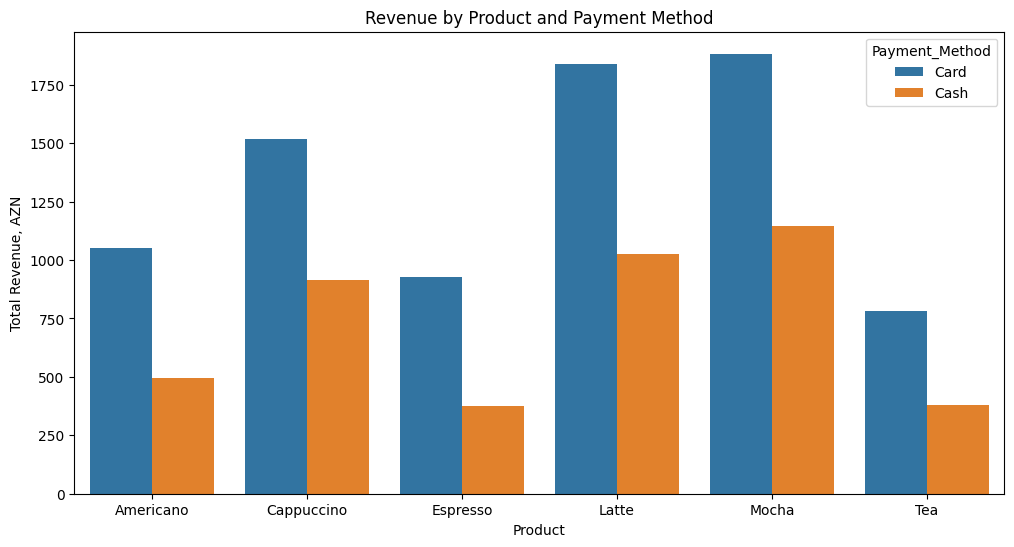

In [46]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=payment_result,
    x="Product",
    y="Total_Revenue",
    hue="Payment_Method"
)

plt.title("Revenue by Product and Payment Method")
plt.xlabel("Product")
plt.ylabel("Total Revenue, AZN")
plt.show()

In [47]:
days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_revenue = dated_df.pivot_table(
    index="Day_Name",
    columns="Product",
    values="Total",
    aggfunc="sum",
    fill_value=0
)

daily_revenue = daily_revenue.reindex(days_order)

print(daily_revenue)

Product    Americano  Cappuccino  Espresso  Latte  Mocha    Tea
Day_Name                                                       
Monday         200.0       174.0     161.0  392.5  406.5  138.0
Tuesday        226.0       276.0     141.5  516.0  286.0  138.0
Wednesday      143.0       264.0     129.5  198.0  364.0  171.0
Thursday       242.0       490.0     143.5  390.5  357.5  156.0
Friday         304.0       280.0     210.0  462.0  530.0  155.0
Saturday       116.0       258.0     126.0  484.0  338.0  150.0
Sunday         256.0       384.0     225.5  187.0  379.5   80.0


In [48]:
pivot = dated_df.pivot_table(
    index="Day_Name",
    columns="Product",
    values="Total",
    aggfunc="sum",
    fill_value=0
)

pivot = pivot.reindex(days_order)

print(pivot)

Product    Americano  Cappuccino  Espresso  Latte  Mocha    Tea
Day_Name                                                       
Monday         200.0       174.0     161.0  392.5  406.5  138.0
Tuesday        226.0       276.0     141.5  516.0  286.0  138.0
Wednesday      143.0       264.0     129.5  198.0  364.0  171.0
Thursday       242.0       490.0     143.5  390.5  357.5  156.0
Friday         304.0       280.0     210.0  462.0  530.0  155.0
Saturday       116.0       258.0     126.0  484.0  338.0  150.0
Sunday         256.0       384.0     225.5  187.0  379.5   80.0


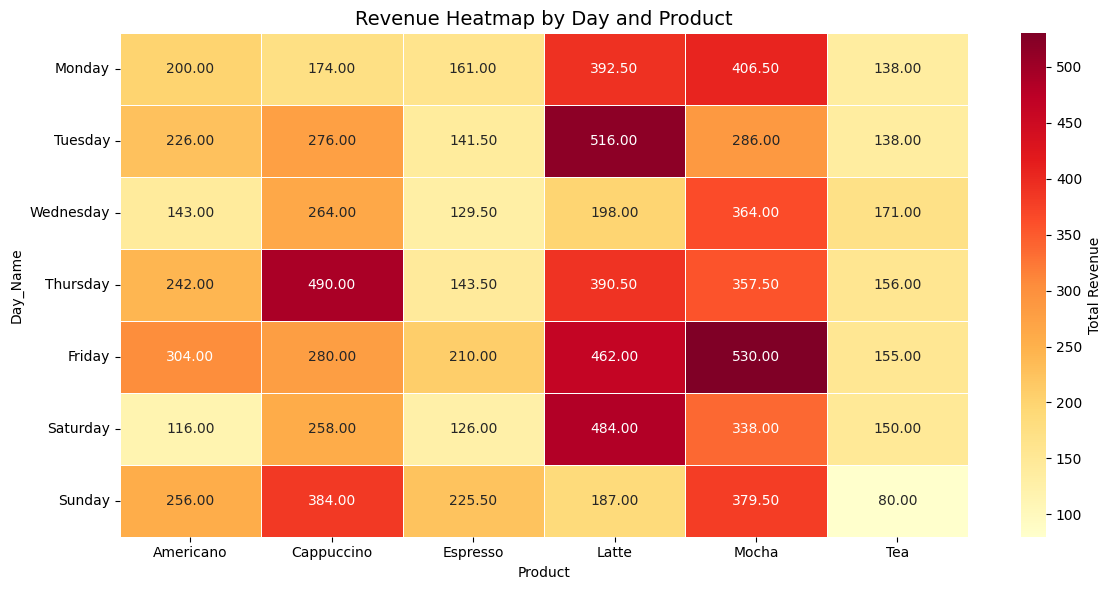

In [49]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Total Revenue"}
)

plt.title("Revenue Heatmap by Day and Product", fontsize=14)
plt.xlabel("Product")
plt.ylabel("Day_Name")

plt.tight_layout()
plt.show()

In [50]:
days_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

pivot = dated_df.pivot_table(
    index="Day_Name",
    columns="Order_Size",
    values="Total",
    aggfunc="sum",
    fill_value=0
)

pivot = pivot.reindex(days_order)
print(pivot)

Order_Size  Large  Medium  Small
Day_Name                        
Monday      365.5   610.0  528.0
Tuesday     417.5   670.0  518.0
Wednesday   301.5   524.0  456.5
Thursday    624.5   715.5  445.5
Friday      531.0   835.5  606.5
Saturday    555.0   508.0  435.0
Sunday      447.5   495.5  577.0


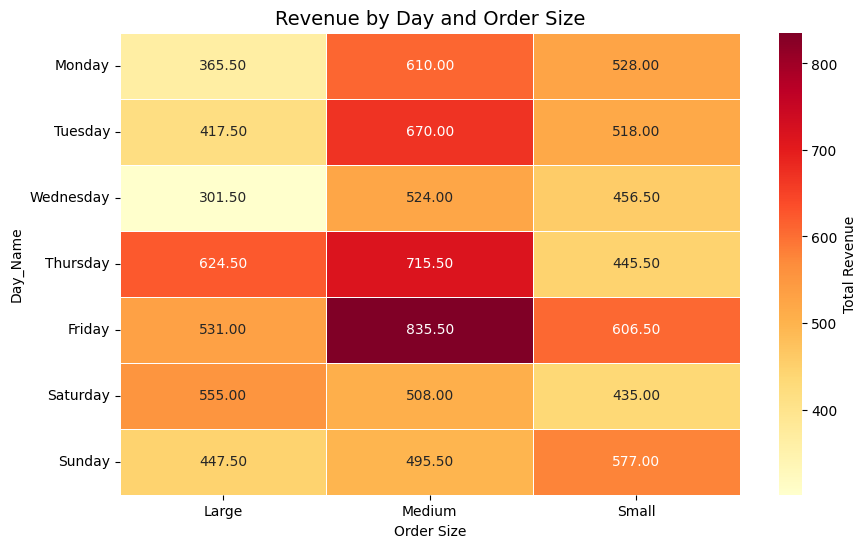

In [51]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Total Revenue"}
)

plt.title("Revenue by Day and Order Size", fontsize=14)
plt.xlabel("Order Size")
plt.ylabel("Day_Name")
plt.show()

**Finding:** Comparing products across days, payment methods and order sizes helps identify opportunities for targeted promotions.

## 9. Order segmentation

In [52]:
segment1 = dated_df[
    (dated_df["Is_Weekend"] == True) &
    (dated_df["Order_Size"] == "Large") &
    (dated_df["Revenue_Category"] == "High Revenue")
]

print("Number of orders:", len(segment1))
print("Total revenue:", segment1["Total"].sum())
print("Most ordered product:", segment1["Product"].mode().iloc[0] if not segment1["Product"].mode().empty else "None")
print("Average quantity:", segment1["Quantity"].mean())
print("Average revenue:", segment1["Total"].mean())

Number of orders: 30
Total revenue: 905.0
Most ordered product: Latte
Average quantity: 5.466666666666667
Average revenue: 30.166666666666668


In [53]:
segment2 = dated_df[
    (dated_df["Is_Weekend"] == False) &
    (dated_df["Order_Size"] == "Small") &
    (dated_df["Revenue_Category"] == "Low Revenue")
]

print("Number of orders:", len(segment2))
print("Total revenue:", segment2["Total"].sum())
print("Most ordered product:", segment2["Product"].mode().iloc[0] if not segment2["Product"].mode().empty else "None")
print("Average quantity:", segment2["Quantity"].mean())
print("Average revenue:", segment2["Total"].mean())

Number of orders: 340
Total revenue: 2441.0
Most ordered product: Mocha
Average quantity: 1.4794117647058824
Average revenue: 7.179411764705883


In [54]:
segment3 = df[
    (df["Payment_Method"] == "Card") &
    (df["Revenue_Category"] == "High Revenue")
]

print("Number of orders:", len(segment3))
print("Total revenue:", segment3["Total"].sum())
print("Most ordered product:", segment3["Product"].mode().iloc[0] if not segment3["Product"].mode().empty else "None")
print("Average quantity:", segment3["Quantity"].mean())
print("Average revenue:", segment3["Total"].mean())

Number of orders: 116
Total revenue: 3194.5
Most ordered product: Latte
Average quantity: 4.827586206896552
Average revenue: 27.538793103448278


In [55]:
segment4 = df[
    (df["Payment_Method"] == "Cash") &
    (df["Order_Size"] == "Large")
]

print("Number of orders:", len(segment4))
print("Total revenue:", segment4["Total"].sum())
print("Most ordered product:", segment4["Product"].mode().iloc[0] if not segment4["Product"].mode().empty else "None")
print("Average quantity:", segment4["Quantity"].mean())
print("Average revenue:", segment4["Total"].mean())

Number of orders: 54
Total revenue: 1486.5
Most ordered product: Latte
Average quantity: 5.407407407407407
Average revenue: 27.52777777777778


##  Business recommendations

- Promote lower-selling products through discounts or bundles.
- Maintain convenient card payment options.
- Plan inventory and staffing around observed sales patterns.
- Test targeted promotions by product and day of week.


## Limitations

- 106 orders have missing or invalid dates; they are retained in overall metrics but excluded from date-based analyses.
- 21 orders have missing product names, representing 218.50 AZN of recorded revenue. They are excluded from named-product comparisons but retained in overall metrics.
- 65 records have a recorded Total that differs from Quantity × Price. Recorded Total is retained because the underlying transaction details are unavailable; revenue figures are therefore reported rather than independently reconciled.
- Customer names are not needed for this analysis and are removed before analysis.
- Historical patterns do not guarantee future customer behavior. Promotions should be tested before implementation.